In [1]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

In [2]:
df = pd.read_csv('svmspam.csv')

In [3]:
df

,word_count,exclamation_marks,capital_word_ratio,link_count,dollar_sign_count,spam_word_score,sender_reputation,has_attachment,subject_length,numeric_ratio,is_spam
0,122,5,0.606277,6,5,0.221209,0.080115,1,67,0.350126,1
1,455,10,0.011515,1,2,0.987668,0.894817,1,25,0.292905,1
2,368,14,0.092858,9,6,0.944059,0.547592,1,56,0.293240,1
3,290,0,0.036802,5,1,0.039427,0.817298,0,59,0.348835,0
4,126,8,0.032583,2,1,0.705575,0.452318,1,30,0.464808,1
...,...,...,...,...,...,...,...,...,...,...,...
295,299,6,0.370028,0,7,0.870969,0.519060,0,65,0.474054,0
296,344,2,0.597977,7,0,0.714087,0.067613,0,14,0.222623,1
297,391,11,0.029347,2,1,0.801728,0.800357,0,54,0.394401,0
298,117,9,0.201950,1,0,0.339450,0.233712,1,7,0.319803,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   word_count          300 non-null    int64  
 1   exclamation_marks   300 non-null    int64  
 2   capital_word_ratio  300 non-null    float64
 3   link_count          300 non-null    int64  
 4   dollar_sign_count   300 non-null    int64  
 5   spam_word_score     300 non-null    float64
 6   sender_reputation   300 non-null    float64
 7   has_attachment      300 non-null    int64  
 8   subject_length      300 non-null    int64  
 9   numeric_ratio       300 non-null    float64
 10  is_spam             300 non-null    int64  
dtypes: float64(4), int64(7)
memory usage: 25.9 KB


In [5]:
df.describe()

,word_count,exclamation_marks,capital_word_ratio,link_count,dollar_sign_count,spam_word_score,sender_reputation,has_attachment,subject_length,numeric_ratio,is_spam
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.00000
mean,260.790000,6.676667,0.401364,4.496667,3.366667,0.515648,0.499861,0.536667,48.453333,0.245252,0.54000
std,135.105035,4.392772,0.243596,2.837280,2.311572,0.303501,0.286790,0.499487,27.840825,0.149257,0.49923
min,21.000000,0.000000,0.008670,0.000000,0.000000,0.006386,0.004940,0.000000,5.000000,0.000094,0.00000
25%,149.000000,3.000000,0.169648,2.000000,1.000000,0.232638,0.237544,0.000000,24.000000,0.113150,0.00000
50%,254.000000,6.500000,0.399023,5.000000,3.000000,0.540626,0.511026,1.000000,48.000000,0.237783,1.00000
75%,372.750000,11.000000,0.615856,7.000000,5.000000,0.781474,0.724569,1.000000,71.250000,0.378859,1.00000
max,496.000000,14.000000,0.799774,9.000000,7.000000,0.997934,0.999414,1.000000,99.000000,0.498539,1.00000


In [6]:
df.size

3300

In [7]:
df.shape

(300, 11)

In [8]:
print(df.isna().sum())

word_count            0
exclamation_marks     0
capital_word_ratio    0
link_count            0
dollar_sign_count     0
spam_word_score       0
sender_reputation     0
has_attachment        0
subject_length        0
numeric_ratio         0
is_spam               0
dtype: int64


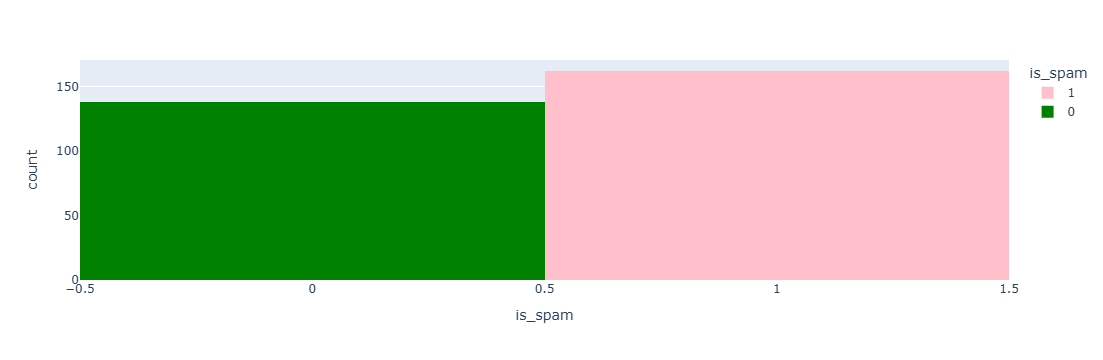

In [9]:
px.histogram(data_frame=df, x='is_spam', color='is_spam',color_discrete_sequence=['pink', 'green'])

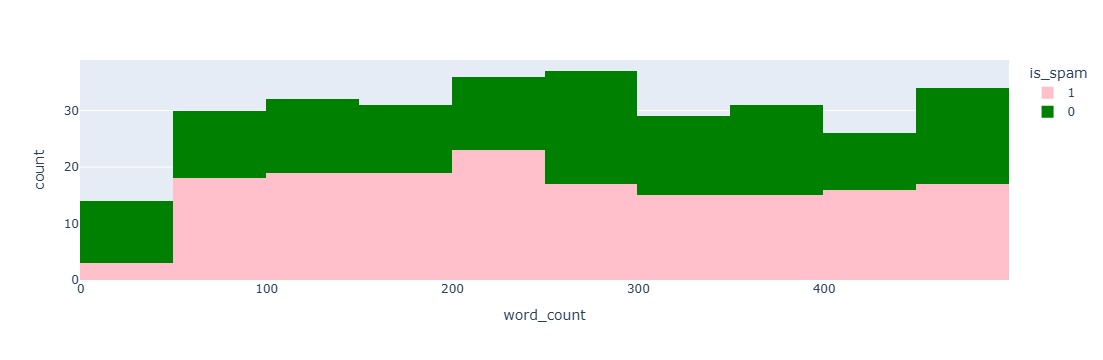

In [10]:
px.histogram(data_frame=df, x='word_count', color='is_spam',color_discrete_sequence=['pink', 'green'])

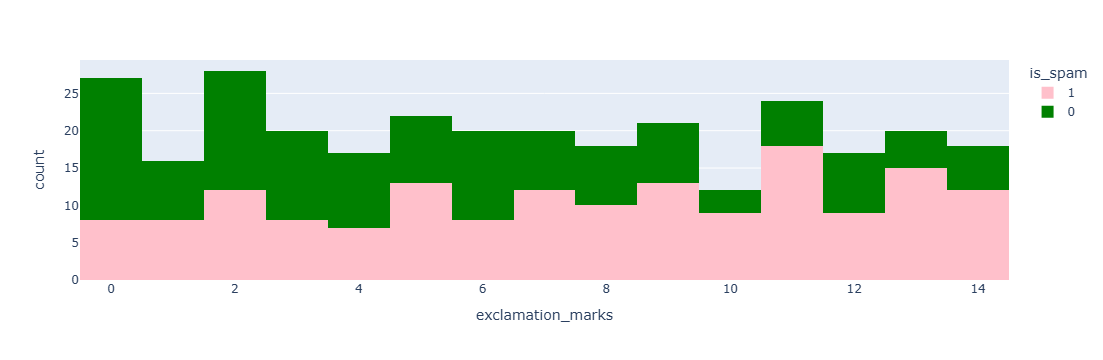

In [11]:
px.histogram(data_frame=df, x='exclamation_marks', color='is_spam',color_discrete_sequence=['pink', 'green'])

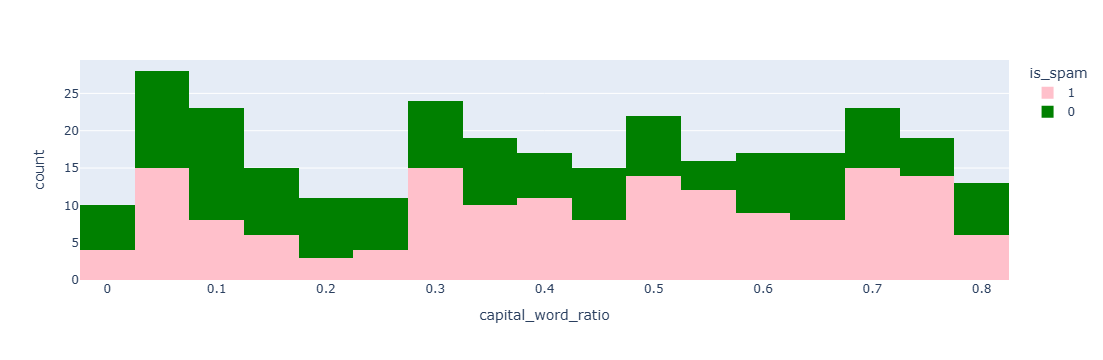

In [12]:
px.histogram(data_frame=df, x='capital_word_ratio', color='is_spam',color_discrete_sequence=['pink', 'green'])

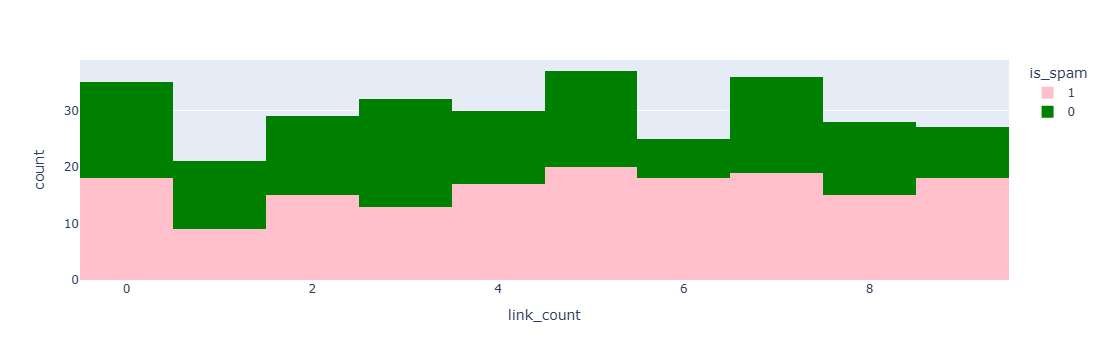

In [13]:
px.histogram(data_frame=df, x='link_count', color='is_spam',color_discrete_sequence=['pink', 'green'])

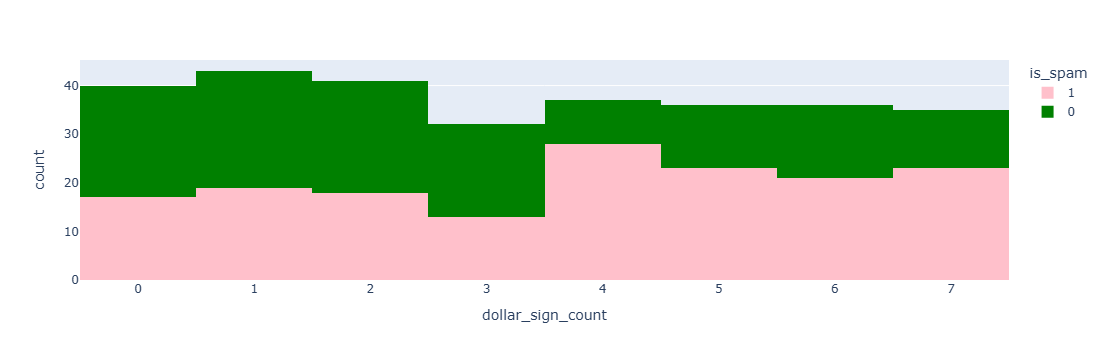

In [14]:
px.histogram(data_frame=df, x='dollar_sign_count', color='is_spam',color_discrete_sequence=['pink', 'green'])

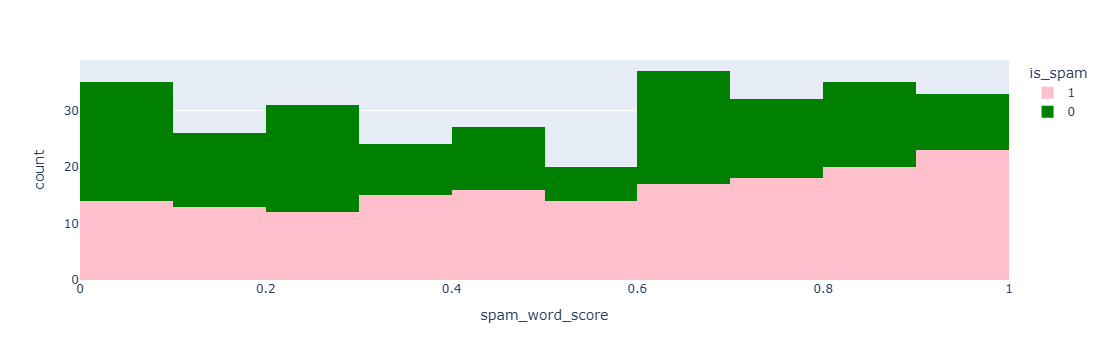

In [15]:
px.histogram(data_frame=df, x='spam_word_score', color='is_spam',color_discrete_sequence=['pink', 'green'])

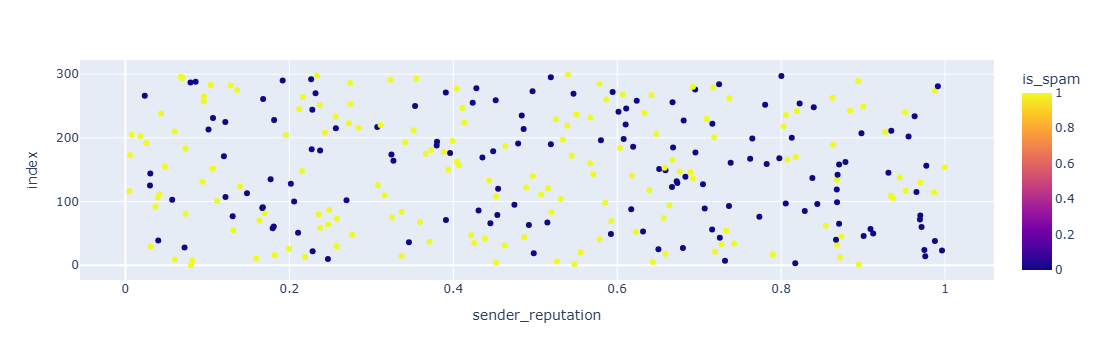

In [16]:
px.scatter(data_frame=df,x='sender_reputation',color='is_spam',color_discrete_sequence=['red', 'green'])

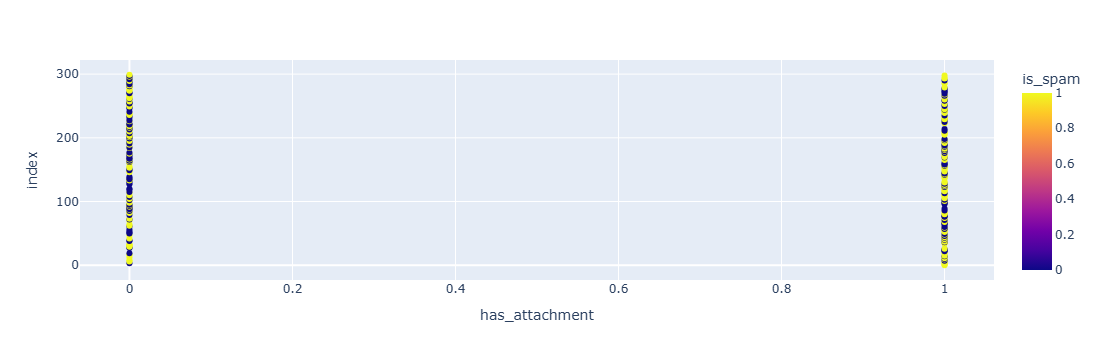

In [17]:
px.scatter(data_frame=df,x='has_attachment',color='is_spam',color_discrete_sequence=['pink', 'green'])

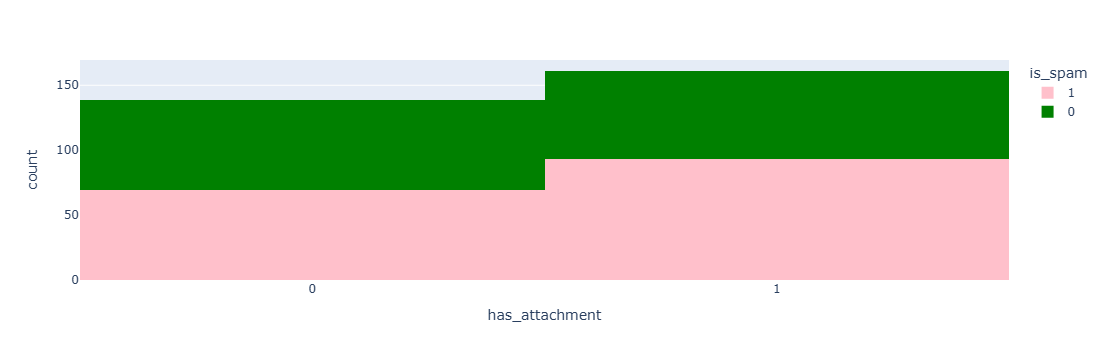

In [18]:
px.histogram(data_frame=df, x='has_attachment', color='is_spam',color_discrete_sequence=['pink', 'green'])

In [19]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
295    False
296    False
297    False
298    False
299    False
Length: 300, dtype: bool

In [20]:
df['is_spam'] = (df['is_spam'] == '1').astype(int) #encode the label into 1/0

In [21]:
corr = df.corr()

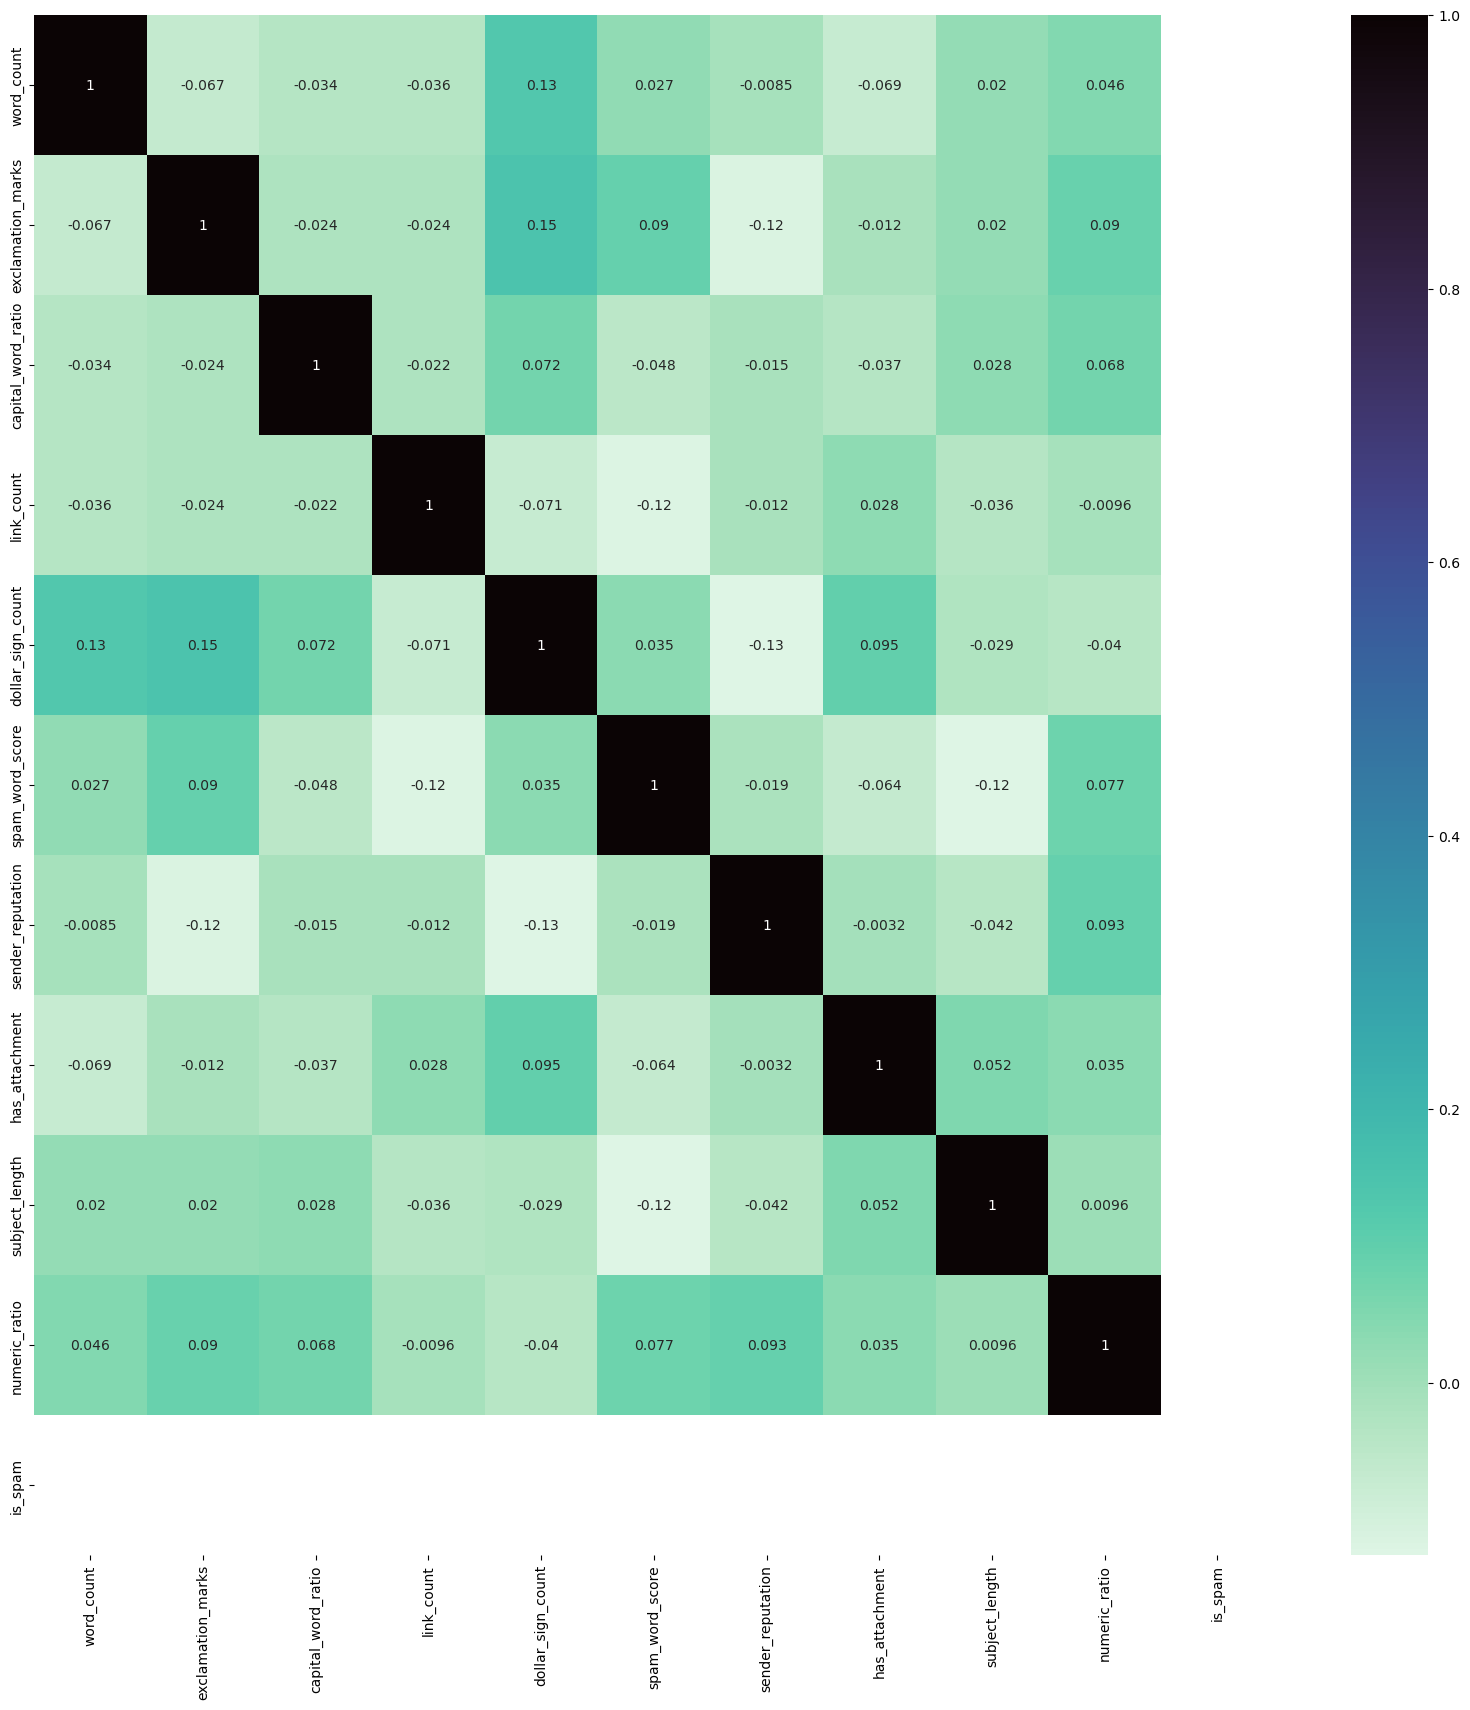

In [22]:
plt.figure(figsize=(20,20))
sns.heatmap(corr, cmap='mako_r', annot = True)
plt.show()

In [23]:
cor_target = abs(corr["is_spam"])

In [24]:
relevant_features = cor_target[cor_target>0.2]

In [25]:
names = [index for index, value in relevant_features.items()]

In [26]:
names = df.columns.tolist()

if 'is_spam' in names:
    names.remove('is_spam')
print(names)

['word_count', 'exclamation_marks', 'capital_word_ratio', 'link_count', 'dollar_sign_count', 'spam_word_score', 'sender_reputation', 'has_attachment', 'subject_length', 'numeric_ratio']


In [27]:
X = df[names].values
y = df['is_spam']

In [28]:
def scale(X):
    """
    Standardizes the data in the array X.

    Parameters:
        X (numpy.ndarray): Features array of shape (n_samples, n_features).

    Returns:
        numpy.ndarray: The standardized features array.
    """
    # Calculate the mean and standard deviation of each feature
    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0)

    # Standardize the data
    X = (X - mean) / std
    return X
X = scale(X)

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42) #split the  data into traing and validating

In [30]:
print(X_test.shape)

(60, 10)


In [31]:
print(y_test.shape)

(60,)


In [32]:
print(X_train.shape)

(240, 10)


In [33]:
print(y_train.shape)

(240,)


In [34]:
import numpy as np
print(np.unique(y_train))

[0]


In [35]:
from sklearn.svm import SVM
from sklearn.metrics import accuracy_score
skmodel = SVC()
skmodel.fit(X_train, y_train)
sk_predictions = skmodel.predict(X_test)

print("accuracy:",(y_test, sk_predictions))

ImportError: cannot import name 'SVM' from 'sklearn.svm' (C:\Users\arath\anaconda3\Lib\site-packages\sklearn\svm\__init__.py)

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

skmodel = SVC()
skmodel.fit(X_train, y_train)

sk_predictions = skmodel.predict(X_test)

print("Accuracy:", accuracy_score(y_test, sk_predictions))

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import numpy as np

# Check class distribution
print("Classes in y:", np.unique(y))
print("Class counts:\n", y.value_counts())

# Train-test split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Verify training set has more than one class
print("\nClasses in y_train:", np.unique(y_train))

if len(np.unique(y_train)) > 1:
    skmodel = SVC()
    skmodel.fit(X_train, y_train)

    sk_predictions = skmodel.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, sk_predictions))
else:
    print("Error: y_train contains only one class. Check your dataset or target variable.")